# Trabajo 5 · Identificación de estrés con señales fisiológicas (WESAD)
**Entornos Inteligentes**
## Análisis visual, panel del espejo e inferencia
Este notebook parte de lo que exporta `01_Entrenamiento.ipynb` (carpeta `outputs/`), que hay que ejecutar **completo** antes.

**Índice**
1. Carga de los ficheros del Notebook 1
2. Análisis visual del estrés (distribuciones, firma fisiológica, PCA, señales por sujeto, mapa sujetos × tiempo)
3. Rendimiento del modelo (ROC, probabilidad por condición, F1 por sujeto)
4. Simulación del panel del espejo (umbrales, persistencia, cooldown)
5. Inferencia en vivo con el modelo final

In [ ]:
import os, warnings
import numpy as np
import pandas as pd
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import ipywidgets as widgets
from IPython.display import display
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_curve, roc_auc_score

warnings.filterwarnings("ignore")
mpl.rcParams["figure.dpi"] = 110
sns.set_theme(style="whitegrid", context="notebook")

OUT_POSTER = os.environ.get("OUT_POSTER", "./outputs")      # misma carpeta que el Notebook 1
COND_ORDER = ["Baseline", "Amusement", "Meditation", "Stress"]
COND_COLORS = {"Baseline": "#4c72b0", "Amusement": "#dd8452", "Meditation": "#55a868", "Stress": "#c44e52"}

/Users/marcfax/Desktop/EI/.venv/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


## 1. Carga de los ficheros del Notebook 1

In [2]:
FILES = ["dataset_features.csv", "OOF_best_model.csv", "OOF_modelos_principales.csv",
         "resultados_por_sujeto.csv", "modelo_final.pkl"]
missing = [f for f in FILES if not os.path.exists(os.path.join(OUT_POSTER, f))]
if missing:
    raise FileNotFoundError(f"Faltan {missing} en '{OUT_POSTER}'. Ejecuta primero el Notebook 1 completo.")

def load(name):
    return os.path.join(OUT_POSTER, name)

DF       = pd.read_csv(load("dataset_features.csv"))        # features por ventana (sin normalizar) + Cond + Label
OOF_BEST = pd.read_csv(load("OOF_best_model.csv"))          # P(estrés) fuera de muestra (LOSO) del modelo elegido
OOF_ALL  = pd.read_csv(load("OOF_modelos_principales.csv"))
RES_SUJ  = pd.read_csv(load("resultados_por_sujeto.csv"))
META     = joblib.load(load("modelo_final.pkl"))            # modelo final reentrenado con todos los sujetos

BEST, COLS = META["name"], META["cols"]
STEP_SEC, WINDOW_SEC = META["step_sec"], META["window_sec"]
SUJETOS = sorted(DF.Subject.unique(), key=lambda s: int(s[1:]))

TS_MODEL = None
if META["kind"] == "seq":
    import torch
    TS_MODEL = torch.jit.load(load(META["torchscript"]), map_location="cpu").eval()

print(f"Modelo elegido: {BEST} ({META['kind']}) | {len(DF)} ventanas de {WINDOW_SEC} s (paso {STEP_SEC} s) | {len(SUJETOS)} sujetos")

Modelo elegido: XGBoost (classic) | 1499 ventanas de 60 s (paso 30 s) | 15 sujetos


In [3]:
# utilidades compartidas 
COND_PATCHES = [Patch(color=COND_COLORS[c], alpha=0.35, label=c) for c in COND_ORDER]

def shade_conditions(ax, d, alpha=0.18):
    """Sombrea el fondo según la condición real (d ordenado por Time)."""
    t, c = d.Time.values / 60, d.Cond.values
    half = STEP_SEC / 120
    start = 0
    for i in range(1, len(d) + 1):
        if i == len(d) or c[i] != c[start]:
            ax.axvspan(t[start] - half, t[i - 1] + half, color=COND_COLORS[c[start]], alpha=alpha, lw=0)
            start = i

def predict_session(d):
    """P(estrés) del modelo final para cada ventana de una sesión ordenada por tiempo.
    NaN donde un modelo secuencial aún no tiene suficientes ventanas consecutivas."""
    if META["kind"] == "classic":
        return META["model"].predict_proba(d[COLS])[:, 1]
    L, t, X = META["seq_len"], d.Time.values, d[COLS].values.astype(float)
    p = np.full(len(d), np.nan)
    for i in range(L - 1, len(d)):
        if np.all(np.diff(t[i - L + 1:i + 1]) == STEP_SEC):
            seq = META["scaler"].transform(X[i - L + 1:i + 1])[None, :, :]
            with torch.no_grad():
                p[i] = TS_MODEL(torch.tensor(seq, dtype=torch.float32)).item()
    return p

## 2. Análisis visual del estrés
Qué cambia en el cuerpo cuando una persona pasa de reposo a estrés. Las figuras 2.1 y 2.2 normalizan cada feature **dentro de cada sujeto** (z-score de su sesión) para quitar las diferencias de nivel entre personas; es solo para visualizar, el modelo no usa esta normalización.

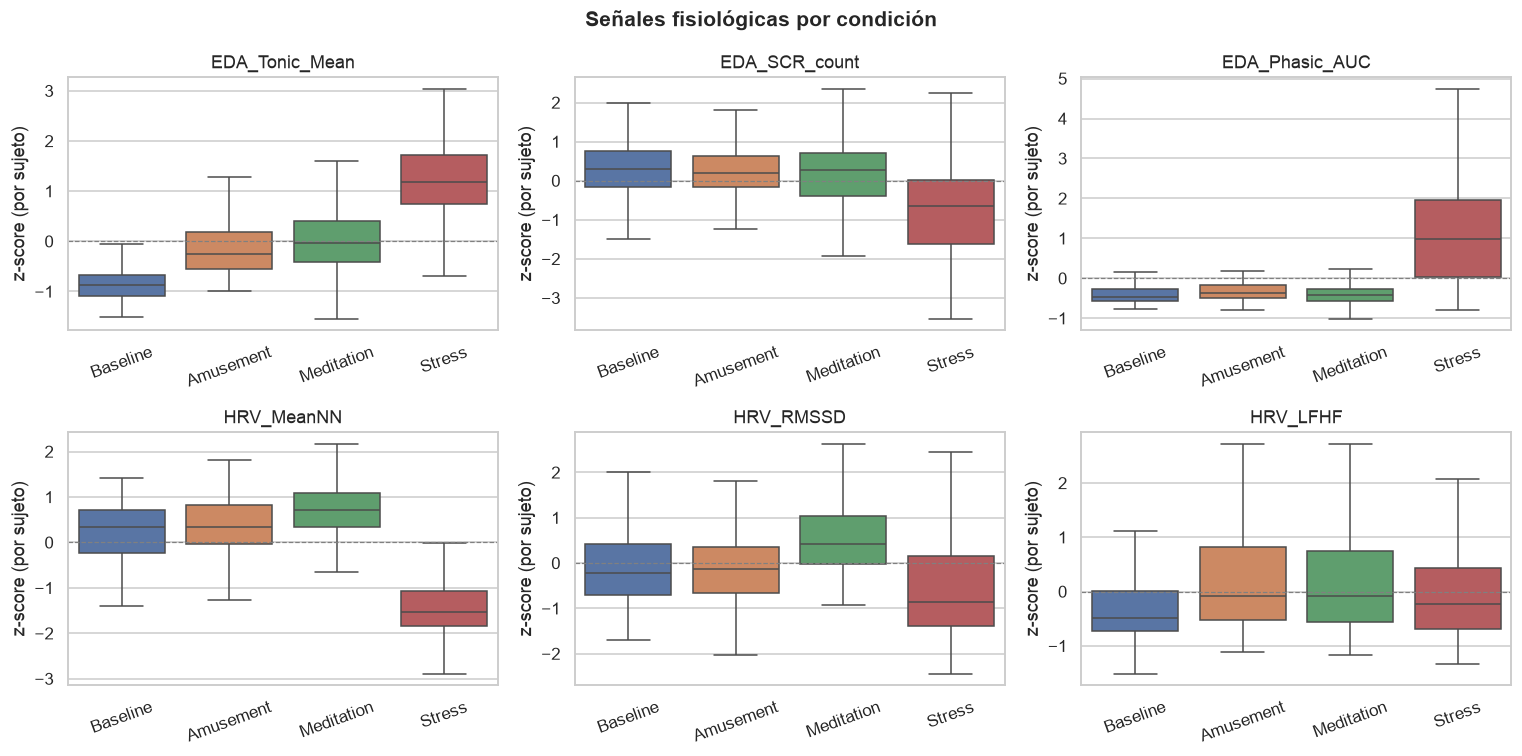

In [4]:
# Distribución de las señales principales por condición (z-score por sujeto)
DF_Z = DF.copy()
DF_Z[COLS] = DF.groupby("Subject")[COLS].transform(lambda s: (s - s.mean()) / (s.std() if s.std() > 0 else 1.0))

KEY_FEATS = [f for f in ["EDA_Tonic_Mean", "EDA_SCR_count", "EDA_Phasic_AUC", "HRV_MeanNN", "HRV_RMSSD", "HRV_LFHF"] if f in COLS]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, f in zip(axes.ravel(), KEY_FEATS):
    sns.boxplot(data=DF_Z, x="Cond", y=f, order=COND_ORDER, palette=[COND_COLORS[c] for c in COND_ORDER],
                showfliers=False, ax=ax)
    ax.axhline(0, color="gray", lw=0.8, ls="--")
    ax.set_title(f); ax.set_xlabel(""); ax.set_ylabel("z-score (por sujeto)")
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Señales fisiológicas por condición", fontsize=14, weight="bold")
plt.tight_layout(); plt.show()

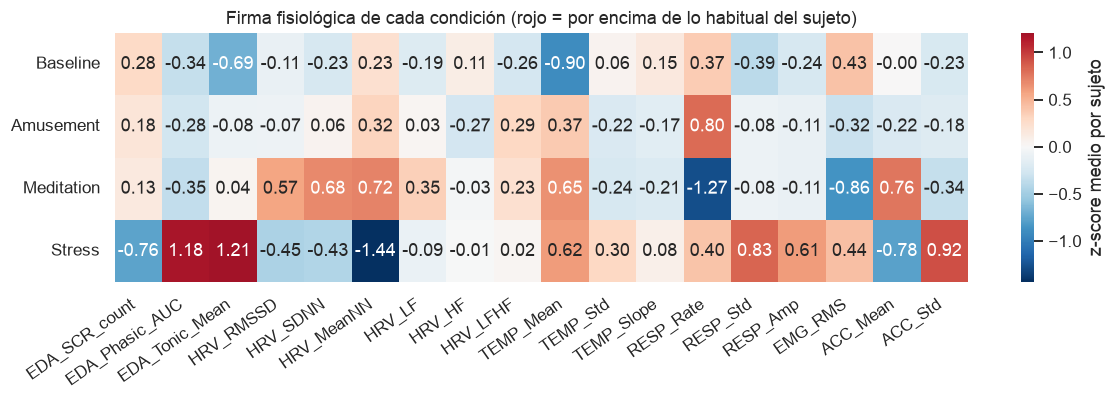

In [5]:
# Firma fisiológica: valor medio de cada feature en cada condición
firma = DF_Z.groupby("Cond")[COLS].mean().reindex(COND_ORDER)
plt.figure(figsize=(11, 3.8))
sns.heatmap(firma, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "z-score medio por sujeto"})
plt.title("Firma fisiológica de cada condición (rojo = por encima de lo habitual del sujeto)")
plt.xticks(rotation=35, ha="right"); plt.yticks(rotation=0); plt.ylabel("")
plt.tight_layout(); plt.show()

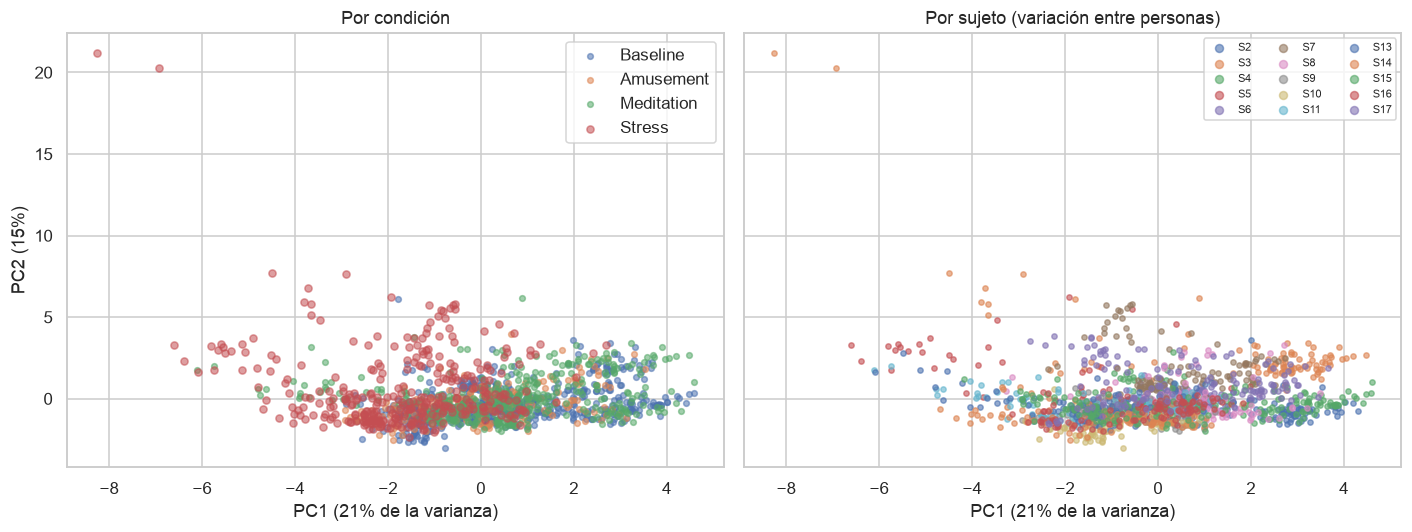

In [6]:
# PCA de las features tal como las ve el modelo: ¿se separa el estrés? ¿y las personas?
Xs = StandardScaler().fit_transform(DF[COLS])
pca = PCA(n_components=2, random_state=42)
Z2 = pca.fit_transform(Xs)
ev = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)
for c in COND_ORDER:
    m = (DF.Cond == c).values
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=22 if c == "Stress" else 14, alpha=0.55, color=COND_COLORS[c], label=c)
axes[0].set_title("Por condición"); axes[0].legend()
for s in SUJETOS:
    m = (DF.Subject == s).values
    axes[1].scatter(Z2[m, 0], Z2[m, 1], s=12, alpha=0.6, label=s)
axes[1].set_title("Por sujeto (variación entre personas)"); axes[1].legend(ncol=3, fontsize=7, markerscale=1.5)
for ax in axes:
    ax.set_xlabel(f"PC1 ({ev[0]:.0%} de la varianza)")
axes[0].set_ylabel(f"PC2 ({ev[1]:.0%})")
plt.tight_layout(); plt.show()

In [7]:
# Señales de un sujeto a lo largo de la sesión 
SIGNALS = [("EDA_Tonic_Mean", "EDA tónica"), ("EDA_SCR_count", "Nº picos SCR"),
           ("HRV_MeanNN", "RR medio (ms)"), ("HRV_RMSSD", "RMSSD (ms)")]
SIGNALS = [s for s in SIGNALS if s[0] in COLS]

@widgets.interact(sujeto=widgets.Dropdown(options=SUJETOS, description="👥 Sujeto:"))
def plot_signals(sujeto=SUJETOS[0]):
    d = DF[DF.Subject == sujeto].sort_values("Time").reset_index(drop=True)
    fig, axes = plt.subplots(len(SIGNALS), 1, figsize=(11, 2.1 * len(SIGNALS)), sharex=True)
    for ax, (col, lab) in zip(axes, SIGNALS):
        shade_conditions(ax, d)
        ax.plot(d.Time / 60, d[col], color="black", lw=1.3)
        ax.set_ylabel(lab, fontsize=9)
    axes[0].legend(handles=COND_PATCHES, ncol=4, loc="lower center", bbox_to_anchor=(0.5, 1.02), fontsize=9)
    axes[-1].set_xlabel("Minutos de sesión")
    fig.suptitle(f"Señales fisiológicas por ventana · {sujeto}", weight="bold", y=1.02)
    plt.tight_layout(); plt.show()

interactive(children=(Dropdown(description='👥 Sujeto:', options=('S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9…

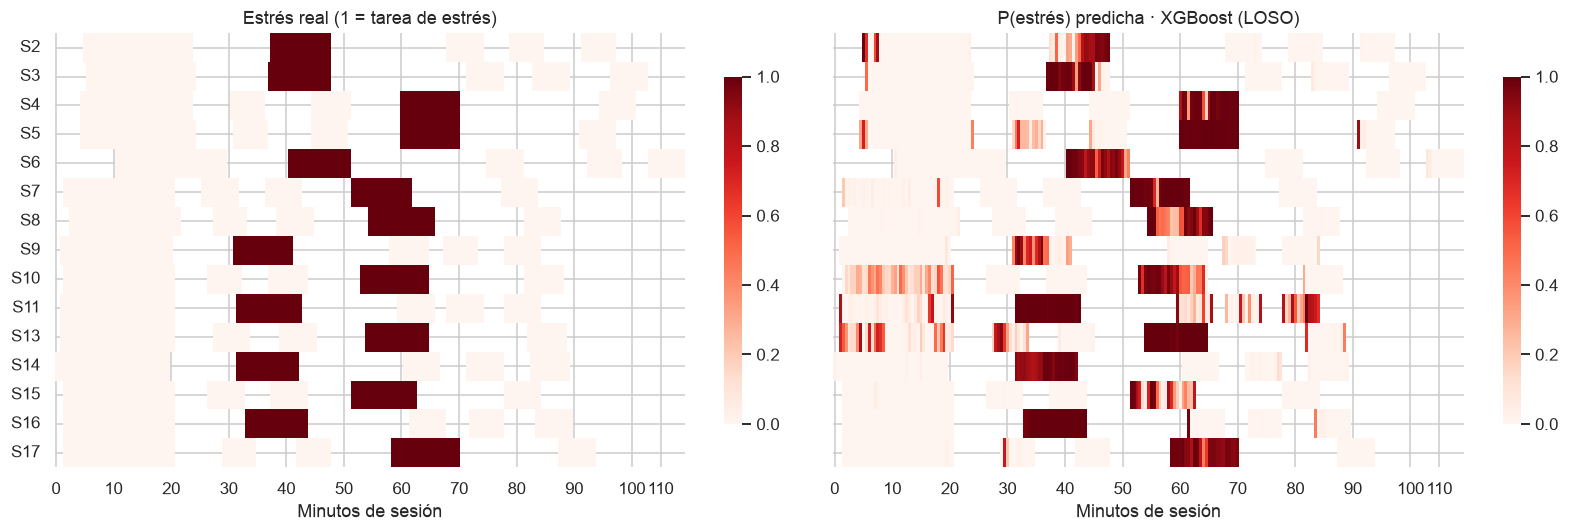

In [8]:
# Mapa sujetos × tiempo: estrés real frente a P(estrés) predicha (LOSO)
piv_y = OOF_BEST.pivot_table(index="Subject", columns="Time", values="y").reindex(SUJETOS)
piv_p = OOF_BEST.pivot_table(index="Subject", columns="Time", values="p").reindex(SUJETOS)
tick_pos = [i for i, t in enumerate(piv_p.columns) if t % 600 == 0]
tick_lab = [int(t // 60) for t in piv_p.columns if t % 600 == 0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharey=True)
for ax, piv, title in [(axes[0], piv_y, "Estrés real (1 = tarea de estrés)"),
                       (axes[1], piv_p, f"P(estrés) predicha · {BEST} (LOSO)")]:
    sns.heatmap(piv, ax=ax, cmap="Reds", vmin=0, vmax=1, xticklabels=False, cbar_kws={"shrink": 0.8})
    ax.set_xticks([p + 0.5 for p in tick_pos]); ax.set_xticklabels(tick_lab, rotation=0)
    ax.set_title(title); ax.set_xlabel("Minutos de sesión"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 3. Rendimiento del modelo
Todo con probabilidades **fuera de muestra** (LOSO): cada sujeto se predice con un modelo que no lo ha visto.

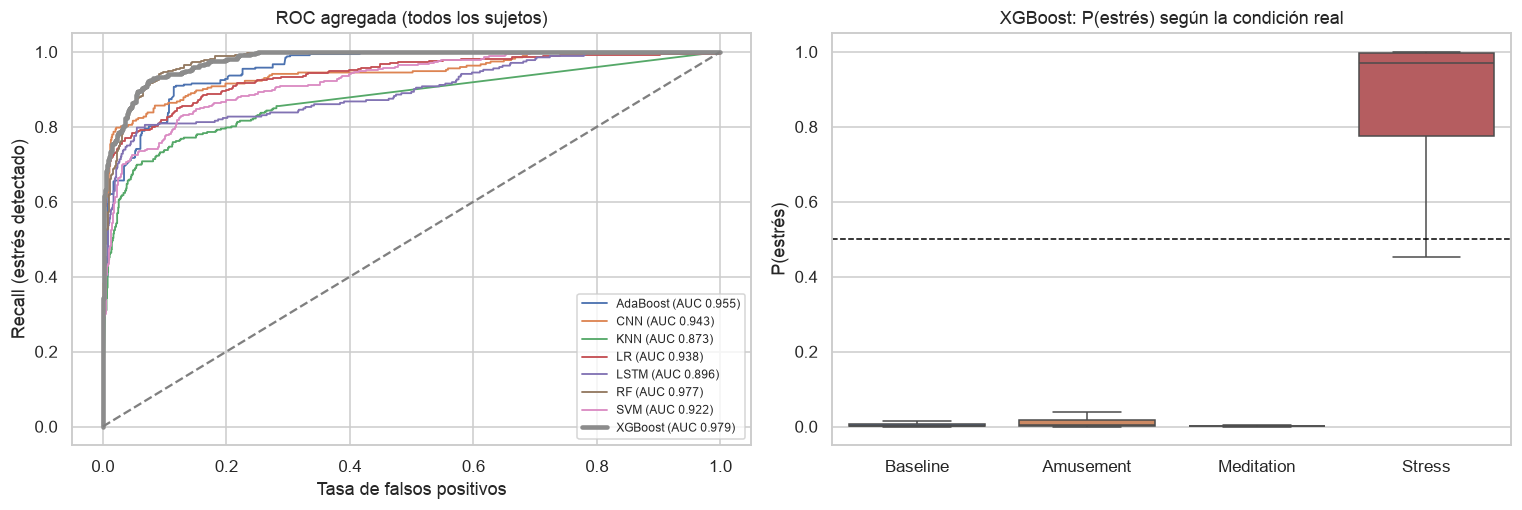

In [9]:
# Curvas ROC de los modelos principales y probabilidad predicha por condición
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for m, g in OOF_ALL.groupby("Modelo"):
    fpr, tpr, _ = roc_curve(g.y, g.p)
    axes[0].plot(fpr, tpr, lw=3 if m == BEST else 1.2, label=f"{m} (AUC {roc_auc_score(g.y, g.p):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_xlabel("Tasa de falsos positivos"); axes[0].set_ylabel("Recall (estrés detectado)")
axes[0].set_title("ROC agregada (todos los sujetos)"); axes[0].legend(fontsize=8, loc="lower right")

sns.boxplot(data=OOF_BEST, x="Cond", y="p", order=COND_ORDER, palette=[COND_COLORS[c] for c in COND_ORDER],
            showfliers=False, ax=axes[1])
axes[1].axhline(0.5, color="black", ls="--", lw=1)
axes[1].set_title(f"{BEST}: P(estrés) según la condición real"); axes[1].set_xlabel(""); axes[1].set_ylabel("P(estrés)")
plt.tight_layout(); plt.show()

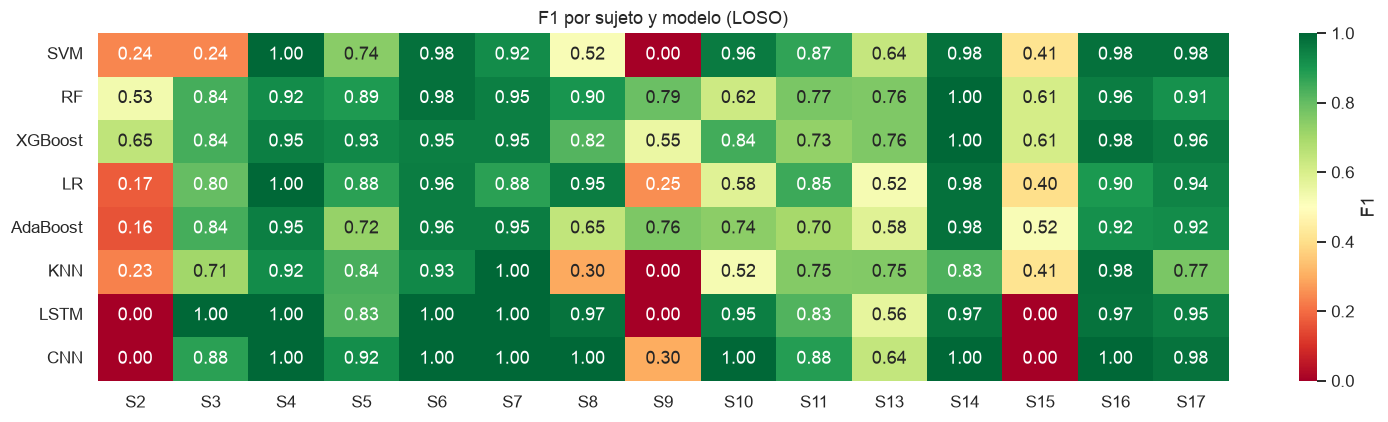

In [10]:
# F1 por sujeto y modelo: quién es difícil de predecir
nombres = OOF_ALL.Modelo.unique().tolist()
f1 = (RES_SUJ[RES_SUJ.Modelo.isin(nombres)]
      .pivot(index="Modelo", columns="Subject", values="F1")
      .reindex(index=nombres, columns=SUJETOS))
plt.figure(figsize=(14, 4))
sns.heatmap(f1, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, cbar_kws={"label": "F1"})
plt.title("F1 por sujeto y modelo (LOSO)"); plt.xlabel(""); plt.ylabel("")
plt.tight_layout(); plt.show()

## 4. Simulación del panel del espejo 
Reproduce lo que habría hecho el espejo sobre la sesión de cada persona con las probabilidades LOSO del modelo elegido:
- Cada ventana es **estrés** (P ≥ umbral de estrés), **calma** (P ≤ umbral de calma) o **incierta** (entre ambos).
- Se emite una sugerencia voluntaria cuando hay `persistencia` ventanas de estrés seguidas (cada ventana avanza 30 s), y después se espera `cooldown` ventanas antes de volver a sugerir.
- Una sugerencia es **acierto** si la ventana era de estrés real y **falsa alarma** si no. La **latencia** es el tiempo desde que empieza el estrés hasta la primera sugerencia acertada.

Sirve para buscar el punto entre detectar el estrés a tiempo y no molestar al usuario.

In [11]:
P_STRESS, P_CALM, PERSIST, COOLDOWN = 0.6, 0.4, 3, 10      # valores por defecto del panel (usa la sección 5)
STYLE = {"description_width": "initial"}
STATE_COLORS = {"estres": "#e74c3c", "calma": "#2ecc71", "incierto": "#bdc3c7"}
MSG_CYCLE = [
    "Llevas un rato con señales de tensión. ¿Quieres hacer una pausa de respiración? (opcional)",
    "Señales de tensión sostenidas. ¿Te apetece hacer una pausa breve? (opcional)",
    "Parece que estás bajo presión. ¿Quieres activar música relajante? (opcional)",
]

def window_state(p, p_stress, p_calm):
    if p >= p_stress: return "estres"
    if p <= p_calm:   return "calma"
    return "incierto"

def simulate_panel(d, p_stress, p_calm, persist, cooldown):
    d = d.sort_values("Time").reset_index(drop=True)
    states = [window_state(x, p_stress, p_calm) for x in d.p]
    sug, last, k = [], -10**9, 0
    for i in range(len(d)):
        if i - last < cooldown:
            continue
        recent = states[max(0, i - persist + 1):i + 1]
        if len(recent) == persist and all(s == "estres" for s in recent):
            sug.append((i, MSG_CYCLE[k % len(MSG_CYCLE)]))
            last = i; k += 1
    return d, states, sug

def session_report(d, sug):
    idx = [i for i, _ in sug]
    hits = [i for i in idx if d.y.iloc[i] == 1]
    lat = np.nan
    if hits and (d.y == 1).any():
        lat = (d.Time.iloc[hits[0]] - d.Time[d.y == 1].min()) / 60
    return {"sugerencias": len(idx), "aciertos": len(hits),
            "falsas_alarmas": len(idx) - len(hits), "latencia_min": lat}

def panel_controls(con_sujeto=True):
    w = dict(
        p_stress=widgets.FloatSlider(value=P_STRESS, min=0.5, max=0.95, step=0.05, description="Umbral estrés:", style=STYLE),
        p_calm=widgets.FloatSlider(value=P_CALM, min=0.1, max=0.5, step=0.05, description="Umbral calma:", style=STYLE),
        persist=widgets.IntSlider(value=PERSIST, min=1, max=10, description="Persistencia (ventanas):", style=STYLE),
        cooldown=widgets.IntSlider(value=COOLDOWN, min=1, max=30, description="Cooldown (ventanas):", style=STYLE),
    )
    if con_sujeto:
        w = {"sujeto": widgets.Dropdown(options=SUJETOS, description="Sujeto:"), **w}
    return w

In [12]:
@widgets.interact(**panel_controls())
def interactive_panel(sujeto, p_stress, p_calm, persist, cooldown):
    d, states, sug = simulate_panel(OOF_BEST[OOF_BEST.Subject == sujeto], p_stress, p_calm, persist, cooldown)
    idx = [i for i, _ in sug]
    t = d.Time.values / 60

    fig, (ax, ax2) = plt.subplots(2, 1, figsize=(11, 5.5), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
    shade_conditions(ax, d)
    ax.axhspan(p_calm, p_stress, color="gray", alpha=0.2)
    ax.plot(t, d.p.values, lw=1.5, color="darkblue")
    if idx:
        ax.scatter(t[idx], d.p.values[idx], color="black", marker="v", s=90, zorder=5)
    ax.set_ylim(0, 1.3); ax.set_yticks([0, 0.25, 0.5, 0.75, 1]); ax.set_ylabel("P(estrés)")
    ax.set_title(f"Comportamiento del espejo inteligente · {sujeto}", fontsize=13, weight="bold")
    handles = COND_PATCHES + [
        Patch(color="gray", alpha=0.3, label="Zona de incertidumbre"),
        Line2D([0], [0], color="darkblue", label="P(estrés) predicha"),
        Line2D([0], [0], marker="v", color="w", markerfacecolor="black", markersize=10, label="Sugerencia emitida")]
    ax.legend(handles=handles, loc="upper left", ncol=4, fontsize=8)

    ax2.bar(t, 1, width=STEP_SEC / 60, color=[STATE_COLORS[s] for s in states])
    ax2.set_ylim(0, 1.7); ax2.set_yticks([]); ax2.set_xlabel("Minutos de sesión")
    ax2.legend(handles=[Patch(color=v, label=k.upper()) for k, v in STATE_COLORS.items()],
               loc="upper right", ncol=3, fontsize=8)
    plt.tight_layout(); plt.show()

    r = session_report(d, sug)
    lat = "—" if np.isnan(r["latencia_min"]) else f"{r['latencia_min']:.1f} min"
    print(f"\n {sujeto}: {r['sugerencias']} sugerencias ({r['aciertos']} en estrés real | "
          f"{r['falsas_alarmas']} falsas alarmas) | latencia hasta la primera acertada: {lat}")
    for k, (i, msg) in enumerate(sug, 1):
        tag = "estrés real" if d.y.iloc[i] == 1 else "falsa alarma"
        print(f"   [{k}] min {t[i]:.1f} | {tag} | {msg}")

interactive(children=(Dropdown(description='Sujeto:', options=('S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',…

In [13]:
# Todos los sujetos con los mismos parámetros
@widgets.interact(**panel_controls(con_sujeto=False))
def panel_todos(p_stress, p_calm, persist, cooldown):
    filas = []
    for s in SUJETOS:
        d, _, sug = simulate_panel(OOF_BEST[OOF_BEST.Subject == s], p_stress, p_calm, persist, cooldown)
        filas.append({"Subject": s, **session_report(d, sug)})
    R = pd.DataFrame(filas).set_index("Subject")

    ax = R[["aciertos", "falsas_alarmas"]].plot(kind="bar", stacked=True, color=["#2ecc71", "#e74c3c"], figsize=(11, 3.8))
    ax.set_ylabel("Sugerencias"); ax.set_xlabel("")
    ax.set_title("Sugerencias emitidas por sujeto (verde = en estrés real, rojo = falsa alarma)")
    plt.xticks(rotation=0); plt.tight_layout(); plt.show()

    display(R.round(1))
    print(f"Total: {int(R.sugerencias.sum())} sugerencias | {int(R.aciertos.sum())} | {int(R.falsas_alarmas.sum())} | "
          f"sujetos con estrés detectado: {int(R.aciertos.gt(0).sum())}/{len(R)}")

interactive(children=(FloatSlider(value=0.6, description='Umbral estrés:', max=0.95, min=0.5, step=0.05, style…

## 5. Inferencia en vivo con el modelo final
Simula la llegada de datos de los sensores ventana a ventana: el modelo final calcula P(estrés), el panel la convierte en un estado y decide si emitir una sugerencia con los mismos parámetros por defecto de la sección 4. Si el modelo elegido es secuencial (LSTM/CNN), necesita varias ventanas consecutivas antes de poder predecir.

El modelo final está entrenado con **todos** los sujetos, incluido el que se muestra, así que su probabilidad (línea azul) es optimista. La línea gris discontinua es la probabilidad LOSO (sujeto no visto) y es la que refleja el rendimiento real.

In [14]:
LIVE = {}

def live_session(sujeto):
    if sujeto not in LIVE:
        d = DF[DF.Subject == sujeto].sort_values("Time").reset_index(drop=True)
        d["p_live"] = predict_session(d)
        LIVE[sujeto] = d
    return LIVE[sujeto]

@widgets.interact(
    sujeto=widgets.Dropdown(options=SUJETOS, description="Sujeto:"),
    ventana=widgets.IntSlider(value=0, min=0, max=int(DF.groupby("Subject").size().max()) - 1,
                              description="Ventana (t):", style=STYLE))
def live_inference(sujeto, ventana):
    d = live_session(sujeto)
    if ventana >= len(d):
        print("La ventana seleccionada excede la duración de la sesión.")
        return
    row = d.iloc[ventana]
    p = row.p_live
    if np.isnan(p):
        print(f"Calentando: {BEST} necesita {META.get('seq_len', 1)} ventanas consecutivas para predecir.")
        return

    estado = window_state(p, P_STRESS, P_CALM)
    hist = d.iloc[:ventana + 1].dropna(subset=["p_live"]).rename(columns={"p_live": "p", "Label": "y"})
    _, _, sug = simulate_panel(hist, P_STRESS, P_CALM, PERSIST, COOLDOWN)
    emitida = bool(sug) and sug[-1][0] == len(hist) - 1

    fig, ax = plt.subplots(figsize=(10, 3.2))
    shade_conditions(ax, d)
    ax.axhspan(P_CALM, P_STRESS, color="gray", alpha=0.2)
    ax.plot(d.Time.iloc[:ventana + 1] / 60, d.p_live.iloc[:ventana + 1], color="darkblue", label="P · modelo final (en vivo)")
    oof = OOF_BEST[(OOF_BEST.Subject == sujeto) & (OOF_BEST.Time <= row.Time)].sort_values("Time")
    ax.plot(oof.Time / 60, oof.p, "--", color="gray", label="P · LOSO (sujeto no visto)")
    ax.scatter(row.Time / 60, p, color="black", zorder=5, s=50)
    ax.set_xlim(d.Time.min() / 60 - 0.5, d.Time.max() / 60 + 0.5); ax.set_ylim(0, 1.05)
    ax.set_xlabel("Minutos de sesión"); ax.set_ylabel("P(estrés)")
    ax.set_title(f"Feed del sensor · {sujeto} · t = {row.Time / 60:.1f} min", weight="bold")
    ax.legend(handles=COND_PATCHES + ax.get_legend_handles_labels()[0], loc="upper left", ncol=3, fontsize=8)
    plt.tight_layout(); plt.show()

    print("=" * 50)
    print(f"SENSOR BIOMÉTRICO (t = {row.Time}s) | Sujeto: {sujeto} | Tarea real: {row.Cond}")
    print("-" * 50)
    print(f"MODELO {BEST}: P(estrés) = {p:.2%} → {estado.upper()}")
    print("Sugerencia: " + (sug[-1][1] if emitida else "ninguna en esta ventana"))
    print("=" * 50)

interactive(children=(Dropdown(description='Sujeto:', options=('S2', 'S3', 'S4', 'S5', 'S6', 'S7', 'S8', 'S9',…